本 notebook 是 [M02.7 群论与表示论](../notes/07-group-representation-theory.qmd) 的实例讲解。

1. 1. 群运算、子群与陪集
2. 2. 实球谐与数值 Wigner D
3. 3. 张量积的 1+3+5 分解
4. 4. 能量不变与力等变

在 VS Code 中选择仓库 `.venv` 内核，逐单元运行；运行结果随文件保存。示例使用固定随机种子和合成数据。

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib_inline.backend_inline import set_matplotlib_formats
from scipy.spatial.transform import Rotation
from scipy.special import sph_harm_y

from semiai.plotting import BLUE, GRAY, use_style

use_style()
set_matplotlib_formats("svg")
rng = np.random.default_rng(42)

## 1. 群运算、子群与陪集

用 C4 的整数表示检查复合和逆，再构造二阶子群的陪集。这个有限例子把抽象定义变成明确的操作表。

In [2]:
elements = set(range(4))
subgroup = {0, 2}
cosets = {tuple(sorted((g + h) % 4 for h in subgroup)) for g in elements}
print("C4 的加法表:")
print(np.array([[(a + b) % 4 for b in range(4)] for a in range(4)]))
print("子群:", subgroup, "不同陪集:", sorted(cosets))
assert all((a + b) % 4 in elements for a in elements for b in elements)
assert all((a + (-a) % 4) % 4 == 0 for a in elements)

C4 的加法表:
[[0 1 2 3]
 [1 2 3 0]
 [2 3 0 1]
 [3 0 1 2]]
子群: {0, 2} 不同陪集: [(0, 2), (1, 3)]


读法：群的闭合、单位元和逆可直接核对；陪集把群按子群划分。一般群的左右陪集不同，只有正规子群才能自然构造商群。

## 2. 实球谐与数值 Wigner D

按明确的实基约定生成球谐函数，用一组方向确定旋转矩阵，再在独立方向上验证等变性和群复合。

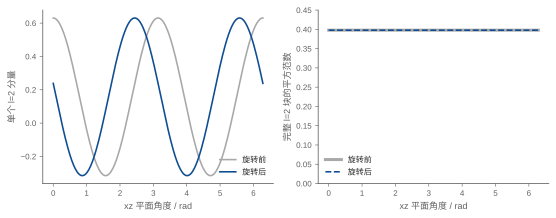

l / 等变误差 / 复合误差 / 正交误差: 1 4.85722573273506e-16 9.962328285051402e-16 1.1230140771728078e-15
l / 等变误差 / 复合误差 / 正交误差: 2 1.887379141862766e-15 5.010276621275221e-15 7.053246380231316e-15
l / 等变误差 / 复合误差 / 正交误差: 3 1.7208456881689926e-15 2.439232332193033e-15 3.345813979762554e-15


In [3]:
def real_harmonics(ell, vectors):
    unit = vectors / np.linalg.norm(vectors, axis=1, keepdims=True)
    theta = np.arccos(np.clip(unit[:, 2], -1, 1))
    phi = np.mod(np.arctan2(unit[:, 1], unit[:, 0]), 2 * np.pi)
    result = []
    for m in range(-ell, ell + 1):
        y = sph_harm_y(ell, abs(m), theta, phi)
        if m < 0:
            result.append(np.sqrt(2) * (-1.0) ** m * y.imag)
        elif m > 0:
            result.append(np.sqrt(2) * (-1.0) ** m * y.real)
        else:
            result.append(y.real)
    return np.column_stack(result)


angles = np.linspace(0, 2 * np.pi, 240)
vectors = np.column_stack([np.sin(angles), np.zeros(len(angles)), np.cos(angles)])
R = Rotation.from_euler("y", 0.7).as_matrix()
Y = real_harmonics(2, vectors)
Yr = real_harmonics(2, vectors @ R.T)
fig, axes = plt.subplots(1, 2, figsize=(7.8, 3.1))
axes[0].plot(angles, Y[:, 2], color=GRAY, label="旋转前")
axes[0].plot(angles, Yr[:, 2], color=BLUE, label="旋转后")
axes[0].set(xlabel="xz 平面角度 / rad", ylabel="单个 l=2 分量")
axes[0].legend()
axes[1].plot(angles, np.sum(Y * Y, axis=1), color=GRAY, lw=3, label="旋转前")
axes[1].plot(angles, np.sum(Yr * Yr, axis=1), color=BLUE, ls="--", label="旋转后")
axes[1].set(xlabel="xz 平面角度 / rad", ylabel="完整 l=2 块的平方范数", ylim=(0, 0.45))
axes[1].legend()
fig.tight_layout()
plt.show()

fit_points = rng.normal(size=(100, 3))
probe = rng.normal(size=(180, 3))
R1 = Rotation.random(random_state=rng).as_matrix()
R2 = Rotation.random(random_state=rng).as_matrix()


def representation(rotation, ell):
    base = real_harmonics(ell, fit_points)
    rotated = real_harmonics(ell, fit_points @ rotation.T)
    return np.linalg.lstsq(base, rotated, rcond=None)[0].T


for ell in (1, 2, 3):
    D1 = representation(R1, ell)
    D2 = representation(R2, ell)
    predicted = real_harmonics(ell, probe) @ D1.T
    actual = real_harmonics(ell, probe @ R1.T)
    equiv = np.max(np.abs(actual - predicted))
    composition = np.linalg.norm(representation(R1 @ R2, ell) - D1 @ D2)
    ortho = np.linalg.norm(D1.T @ D1 - np.eye(2 * ell + 1))
    print("l / 等变误差 / 复合误差 / 正交误差:", ell, equiv, composition, ortho)
    assert max(equiv, composition, ortho) < 1e-10

读法：在同一基约定下，整个 2l+1 维块随旋转混合，块范数不变。独立探针避免只验证用于求解 D 的训练方向；数值求基适合教学，不替代生产级 Wigner D 实现。

## 3. 张量积的 1+3+5 分解

两个三维向量的外积有 9 个分量，分解为迹、反对称部分和对称无迹部分，分别对应 SO(3) 下的 l=0、1、2。

In [4]:
a = rng.normal(size=3)
b = rng.normal(size=3)
T = np.outer(a, b)
scalar = np.trace(T) / 3 * np.eye(3)
antisym = (T - T.T) / 2
symtr = (T + T.T) / 2 - scalar
print("重构误差:", np.linalg.norm(T - scalar - antisym - symtr))
print("对称无迹块的 trace:", np.trace(symtr))
print("迹在旋转前后:", np.trace(T), np.trace(R1 @ T @ R1.T))
reflection = np.diag([-1.0, 1.0, 1.0])
print(
    "叉积的 O(3) 变换误差:",
    np.linalg.norm(
        np.cross(reflection @ a, reflection @ b)
        - np.linalg.det(reflection) * reflection @ np.cross(a, b)
    ),
)
assert np.allclose(T, scalar + antisym + symtr)
assert np.allclose(np.trace(symtr), 0)

重构误差: 0.0
对称无迹块的 trace: -1.1102230246251565e-16
迹在旋转前后: 1.215567938478477 1.2155679384784772
叉积的 O(3) 变换误差: 0.0


读法：Clebsch–Gordan 分解就是把张量积换到不可约块的基。叉积是轴向量，反射下多出 determinant 因子，因此仅标记 l 不足以描述 O(3)，还要说明宇称。

## 4. 能量不变与力等变

在同种粒子的解析成对二次能量上检查平移、旋转和置换。对输出为向量的力，应比较旋转后的向量而非要求数值不变。

In [5]:
positions = rng.normal(size=(7, 3))
shift = np.array([2.0, -1.0, 0.4])
perm = rng.permutation(7)


def energy(r):
    delta = r[:, None, :] - r[None, :, :]
    return np.sum(delta * delta) / 4


def force(r):
    return -len(r) * (r - r.mean(axis=0))


transformed = positions[perm] @ R1.T + shift
print("能量不变误差:", abs(energy(transformed) - energy(positions)))
print("力等变误差:", np.max(np.abs(force(transformed) - force(positions)[perm] @ R1.T)))
print("总力:", force(positions).sum(axis=0))
assert np.allclose(energy(transformed), energy(positions))
assert np.allclose(force(transformed), force(positions)[perm] @ R1.T)

能量不变误差: 1.4210854715202004e-14
力等变误差: 2.1094237467877974e-15
总力: [ 8.88178420e-16  3.55271368e-15 -1.77635684e-15]


读法：能量属于标量输出，力属于逐粒子的向量输出；置换同时重排输入粒子与输出力。不同元素的置换还必须一起重排元素标签。

## 小结

群约束操作的复合，表示约束特征的变换，不可约块组织最小的封闭分量。球谐与 Wigner D 实现旋转结构，Clebsch–Gordan 分解组织张量积；O(3) 还需要宇称，E(3) 还包含平移。